# 🌵 Onde furar os poços? — **Núcleo central do Pajeú (10 municípios)**

Reduzimos o grafo de 18 cidades para o seu **núcleo central de 10** — mantendo o *subgrafo
induzido* (as mesmas arestas < 60 km que já existiam entre elas). É um tamanho doce: 10 qubits,
$2^{10}=1024$ configurações — brute force trivial, e o QAOA já mostra a **transição de escala**.

As 10: Afogados da Ingazeira, Calumbi, Carnaíba, Custódia, Flores, Iguaracy, Ingazeira, Quixaba,
Solidão, Tabira.

## 0. Setup, dados e adjacência (subgrafo induzido do grafo de 18)

In [9]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np, itertools as it
import networkx as nx, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp

PAL={"otimo":"#159a7c","viavel":"#83c9b6","inviavel":"#e08a7d","escuro":"#264653",
     "accent":"#d98324","azul":"#4169d6","cinza":"#9aa4ab","edge":"#dfe4e8"}
INK="#33414a"
plt.rcParams.update({"figure.facecolor":"white","axes.facecolor":"white","figure.dpi":110,
    "font.size":11,"axes.titlesize":12.5,"axes.titleweight":"bold","axes.labelcolor":INK,
    "axes.edgecolor":"#cfd6db","text.color":INK,"xtick.color":"#6b767d","ytick.color":"#6b767d",
    "axes.spines.top":False,"axes.spines.right":False})
def clean(ax):
    for s in ("top","right"): ax.spines[s].set_visible(False)
    ax.grid(axis="y",color="#eef1f3",lw=1.1); ax.set_axisbelow(True); ax.tick_params(length=0); return ax
def halo(t): t.set_path_effects([pe.withStroke(linewidth=2.6,foreground="white")]); return t

cidades=["Afogados da Ingazeira","Calumbi","Carnaíba","Custódia","Flores","Iguaracy",
         "Ingazeira","Quixaba","Solidão","Tabira"]
n=len(cidades)
coord={"Afogados da Ingazeira":(-37.6347,-7.7481),"Calumbi":(-38.1525,-7.9397),
 "Carnaíba":(-37.7947,-7.8060),"Custódia":(-37.6400,-8.0860),"Flores":(-37.9743,-7.8620),
 "Iguaracy":(-37.5140,-7.8363),"Ingazeira":(-37.4599,-7.6773),"Quixaba":(-37.8484,-7.7185),
 "Solidão":(-37.6514,-7.6009),"Tabira":(-37.5377,-7.5837)}
pos={i:coord[cidades[i]] for i in range(n)}

# subgrafo induzido do grafo de 18 (Delaunay ∩ <60km)
Adj=np.array([
 [0,0,1,0,0,1,1,1,1,1],[0,0,0,1,1,0,0,0,0,0],[1,0,0,1,1,1,0,1,0,0],[0,1,1,0,1,1,0,0,0,0],
 [0,1,1,1,0,0,0,1,0,0],[1,0,1,1,0,0,1,0,0,0],[1,0,0,0,0,1,0,0,0,1],[1,0,1,0,1,0,0,0,1,0],
 [1,0,0,0,0,0,0,1,0,1],[1,0,0,0,0,0,1,0,1,0]])
assert (Adj==Adj.T).all()
N={i:sorted([i]+[j for j in range(n) if Adj[i,j]]) for i in range(n)}
g=nx.from_numpy_array(Adj)
print("arestas:",g.number_of_edges(),"| conexo:",nx.is_connected(g))
print("graus:",{cidades[i]:int(Adj[i].sum()) for i in range(n)})


arestas: 19 | conexo: True
graus: {'Afogados da Ingazeira': 6, 'Calumbi': 2, 'Carnaíba': 5, 'Custódia': 4, 'Flores': 4, 'Iguaracy': 4, 'Ingazeira': 3, 'Quixaba': 4, 'Solidão': 3, 'Tabira': 3}


## 1. O grafo de vizinhança

**Afogados da Ingazeira** é o hub (grau 6); **Calumbi** é a mais periférica (grau 2, só liga a
Custódia e Flores). Essa assimetria vai definir a solução.

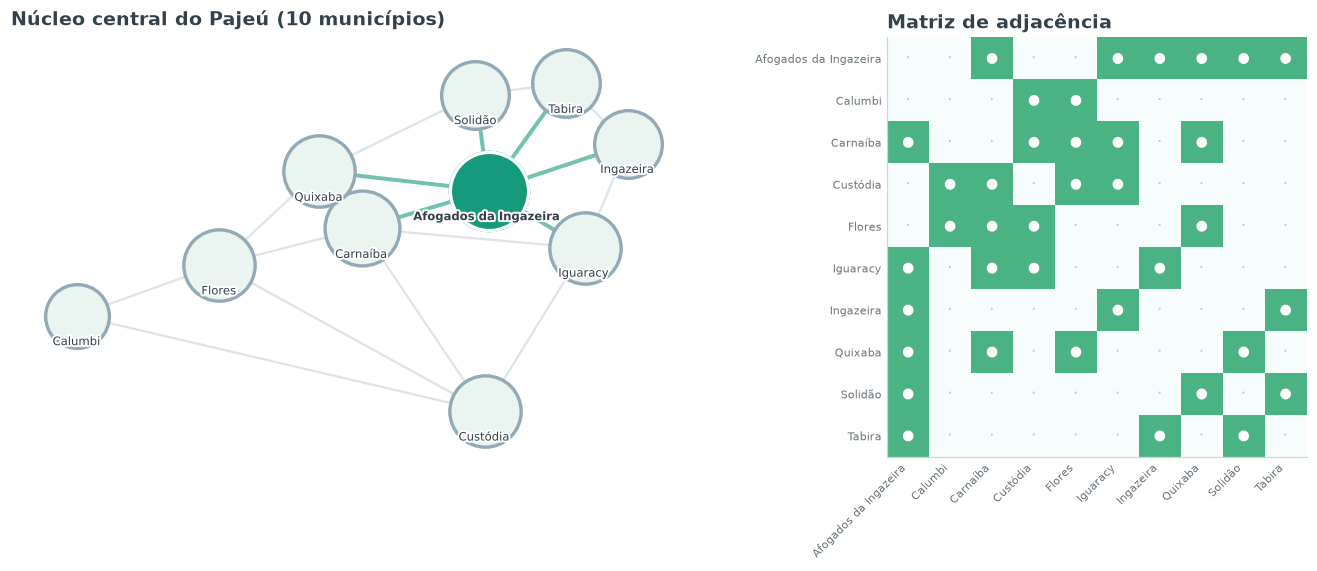

In [10]:
G=nx.relabel_nodes(g,{i:cidades[i] for i in range(n)})
deg=dict(G.degree()); hub=max(deg,key=deg.get)
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(12.5,5.2),gridspec_kw={"width_ratios":[1.35,1]})
e_hub=[(u,v) for u,v in G.edges() if hub in (u,v)]; e_out=[(u,v) for u,v in G.edges() if hub not in (u,v)]
nx.draw_networkx_edges(G,coord,ax=ax1,edgelist=e_out,width=1.5,edge_color=PAL["edge"])
nx.draw_networkx_edges(G,coord,ax=ax1,edgelist=e_hub,width=2.6,edge_color=PAL["otimo"],alpha=0.6)
for c,(x,y) in coord.items():
    w=c==hub
    ax1.scatter([x],[y],s=1300+220*deg[c],color=PAL["otimo"] if w else PAL["nodefill"] if False else ("#eaf5f1"),
                edgecolors=PAL["otimo"] if w else "#93aab6",linewidths=2.2,zorder=3)
    if w: ax1.scatter([x],[y],s=1300+220*deg[c],color=PAL["otimo"],edgecolors="white",linewidths=2.2,zorder=3)
    halo(ax1.text(x,y-0.03,c,ha="center",va="top",fontsize=7.6,fontweight="bold" if w else "normal",color=INK,zorder=5))
ax1.set_title("Núcleo central do Pajeú (10 municípios)",loc="left",pad=8)
xs=[p[0] for p in coord.values()]; ys=[p[1] for p in coord.values()]
mx=(max(xs)-min(xs))*0.12; my=(max(ys)-min(ys))*0.14
ax1.set_xlim(min(xs)-mx,max(xs)+mx); ax1.set_ylim(min(ys)-my,max(ys)+my); ax1.set_axis_off()
ax2.imshow(Adj,cmap="BuGn",vmin=0,vmax=1.7)
ax2.set_xticks(range(n)); ax2.set_yticks(range(n))
ax2.set_xticklabels(cidades,rotation=45,ha="right",fontsize=7.5); ax2.set_yticklabels(cidades,fontsize=7.5)
for i in range(n):
    for j in range(n):
        ax2.text(j,i,"●" if Adj[i,j] else "·",ha="center",va="center",
                 color="white" if Adj[i,j] else "#c2cbd0",fontsize=9 if Adj[i,j] else 12)
ax2.set_title("Matriz de adjacência",loc="left"); ax2.tick_params(length=0)
plt.tight_layout(); plt.show()


## 2. Modelagem (idêntica)

$$\min \sum_i x_i \quad\text{s.a.}\quad \sum_{j\in N[i]} x_j\ge 1\;\forall i \qquad\Longrightarrow\qquad
H_C=B\sum_i x_i + A\sum_i\prod_{u\in N[i]}(1-x_u)$$

Formulação de **Lucas (2014)** com folga: $n+\sum_i M_i = 10+48 = 58$ qubits. Para o QAOA, a
versão **compacta de 10 qubits** (o QAOA aceita os termos de ordem alta).

In [11]:
A_pen,B_cost=8.0,1.0
def xop(i):
    l=["I"]*n; l[n-1-i]="Z"; return SparsePauliOp.from_list([("I"*n,0.5),("".join(l),-0.5)])
Iop=SparsePauliOp.from_list([("I"*n,1.0)]); Zero=SparsePauliOp.from_list([("I"*n,0.0)])
H_cost=B_cost*sum((xop(i) for i in range(n)),Zero)
for i in range(n):
    pr=Iop
    for u in N[i]: pr=pr@(Iop-xop(u))
    H_cost=H_cost+A_pen*pr
H_cost=H_cost.simplify()
print(f"H_C: {len(H_cost)} termos de Pauli em {n} qubits")

# energias (a diagonal de H_C) e verificação
xb=((np.arange(2**n)[:,None]>>np.arange(n))&1)
cov=np.zeros((2**n,n),bool)
for i in range(n): cov[:,i]=xb[:,N[i]].any(1)
energies=(B_cost*xb.sum(1)+A_pen*(~cov).sum(1)).astype(float)
feasible=(~cov).sum(1)==0
print("H_C (Pauli) == energia combinatória ?", np.allclose(np.real(np.diag(H_cost.to_matrix())),energies))


H_C: 216 termos de Pauli em 10 qubits
H_C (Pauli) == energia combinatória ? True


## 3. Solução exata — o gabarito

`argmin` sobre as 1024 energias. O mínimo é **2 poços**, e há **3 soluções ótimas** — todas
incluindo **Afogados** (essencial), com o segundo poço em Calumbi, Custódia ou Flores.

ótimo H=2 -> 2 poços | 3 soluções ótimas:
   • ['Afogados da Ingazeira', 'Calumbi']
   • ['Afogados da Ingazeira', 'Custódia']
   • ['Afogados da Ingazeira', 'Flores']


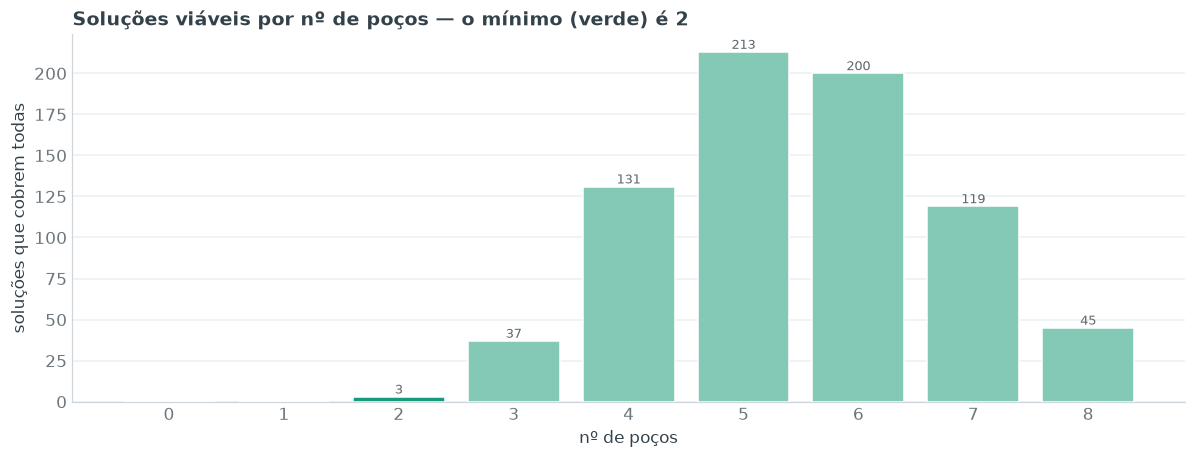

In [12]:
def bits(k): return [(k>>i)&1 for i in range(n)]
def pocos(k): return [cidades[i] for i in range(n) if (k>>i)&1]
gmin=energies.min(); otimos=np.where(energies==gmin)[0]; melhor=int(otimos[0])
wells=[i for i in range(n) if (melhor>>i)&1]
print(f"ótimo H={gmin:.0f} -> {len(wells)} poços | {len(otimos)} soluções ótimas:")
for k in otimos: print("   •",pocos(k))

nw=xb.sum(1); vals=np.arange(0,9)
counts=[int(((nw==w)&feasible).sum()) for w in vals]
fig,ax=plt.subplots(figsize=(11,4.3)); clean(ax)
bars=ax.bar(vals,counts,color=[PAL["otimo"] if w==len(wells) else PAL["viavel"] for w in vals],
            edgecolor="white",width=0.8,zorder=3)
for r,c in zip(bars,counts):
    if c: ax.text(r.get_x()+r.get_width()/2,r.get_height(),str(c),ha="center",va="bottom",fontsize=8.5,color="#5b666d")
ax.set_xticks(vals); ax.set_xlabel("nº de poços"); ax.set_ylabel("soluções que cobrem todas")
ax.set_title("Soluções viáveis por nº de poços — o mínimo (verde) é 2",loc="left")
plt.tight_layout(); plt.show()


## 4. QAOA no Qiskit

Circuito (mostrado com $p=2$): superposição → camada de custo $e^{-i\gamma H_C}$ + mixer $R_X$.

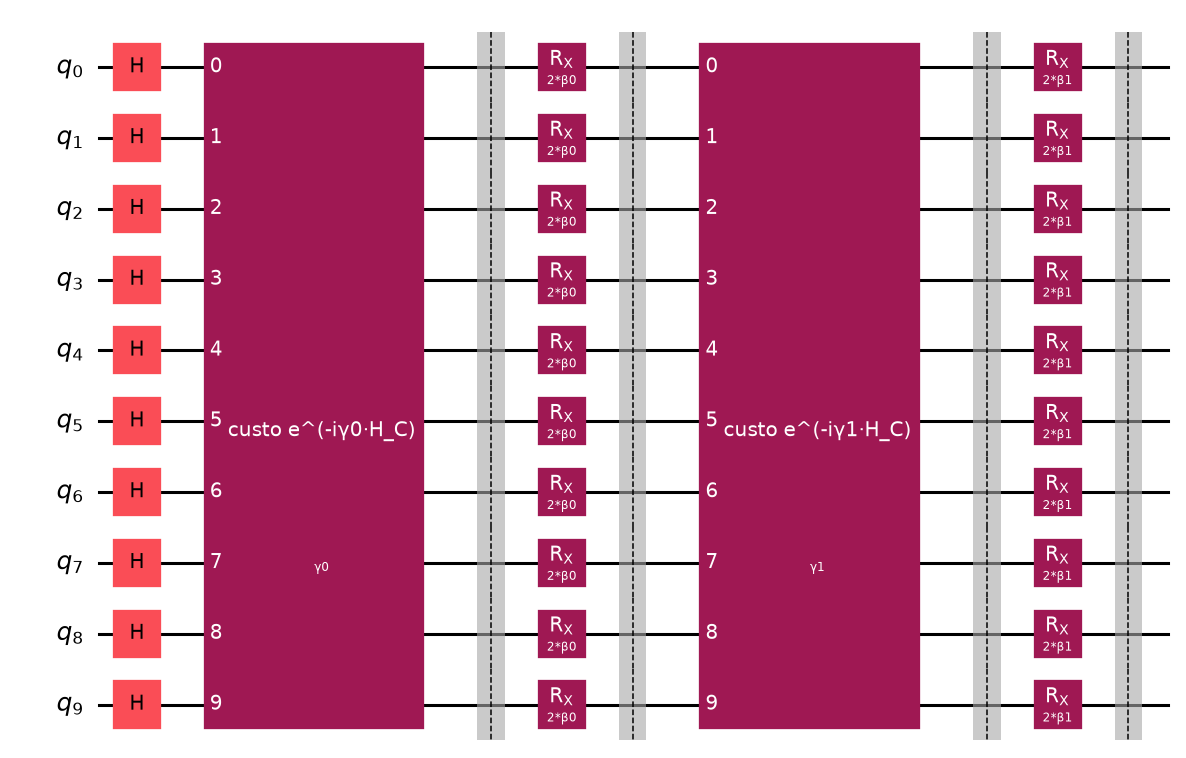

In [13]:
def qaoa_circuit(p):
    gg=[Parameter(f"γ{k}") for k in range(p)]; bb=[Parameter(f"β{k}") for k in range(p)]
    qc=QuantumCircuit(n); qc.h(range(n))
    for k in range(p):
        ev=PauliEvolutionGate(H_cost,time=gg[k]); ev.label=f"custo e^(-iγ{k}·H_C)"
        qc.append(ev,range(n)); qc.barrier()
        for q in range(n): qc.rx(2*bb[k],q)
        qc.barrier()
    return qc,gg,bb
qc_demo,_,_=qaoa_circuit(2)
_=qc_demo.draw("mpl",style="iqp",fold=-1)


### 4.1 Treino e desempenho

Simulador rápido (fases diagonais). A 10 qubits o ótimo é 1 (dos 3) estados em 1024, então além
da razão de aproximação medimos **P(alguma solução ótima)**, **P(viável)** e a **melhor de N
medições** — como o QAOA é usado na prática.

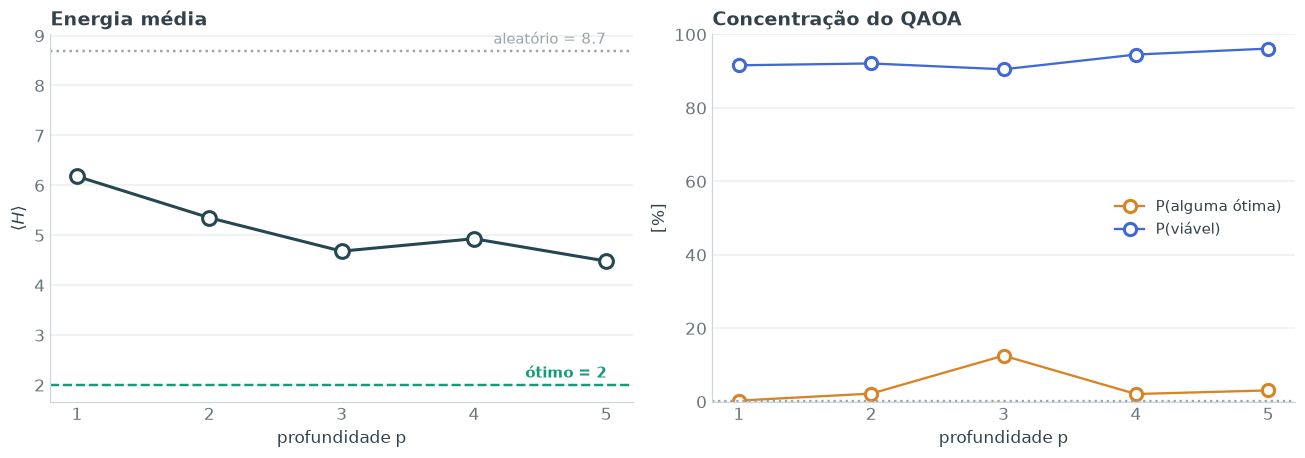

melhor p=3: <H>=4.68 (razão 2.34) | P(ótimo)=0.125 | P(viável)=0.905
melhor de 4096 medições -> QAOA: H=2  (ótimo=2)  ->  a amostragem RECUPERA o ótimo


In [14]:
def rx_all(state,beta):
    c,s=np.cos(beta),-1j*np.sin(beta); st=state.reshape([2]*n)
    for q in range(n):
        st=np.moveaxis(st,q,0); a0,a1=st[0].copy(),st[1].copy()
        st[0]=c*a0+s*a1; st[1]=s*a0+c*a1; st=np.moveaxis(st,0,q)
    return st.reshape(-1)
def qaoa_probs(v,p):
    gg,bb=v[:p],v[p:]; state=np.ones(2**n,complex)/np.sqrt(2**n)
    for k in range(p): state=state*np.exp(-1j*gg[k]*energies); state=rx_all(state,bb[k])
    return np.abs(state)**2
def exp_H(v,p): return float(np.sum(qaoa_probs(v,p)*energies))
def treinar(p,restarts=25,maxiter=300,seed=11):
    rng=np.random.default_rng(seed); best=None
    for _ in range(restarts):
        r=minimize(exp_H,rng.uniform(0,np.pi,2*p),args=(p,),method="COBYLA",options={"maxiter":maxiter})
        if best is None or r.fun<best.fun: best=r
    return best
def melhor_de_N(pr,shots=4096,seed=0): return energies[np.random.default_rng(seed).choice(len(pr),shots,p=pr)].min()

gmask=energies==gmin
Ps=[1,2,3,4,5]
res={p:treinar(p) for p in Ps}
Popt=[qaoa_probs(res[p].x,p)[gmask].sum() for p in Ps]
Pfeas=[qaoa_probs(res[p].x,p)[feasible].sum() for p in Ps]
Hmed=[res[p].fun for p in Ps]

fig,(a1,a2)=plt.subplots(1,2,figsize=(12,4.3)); clean(a1); clean(a2)
a1.plot(Ps,Hmed,"-",color=PAL["escuro"],lw=2); a1.plot(Ps,Hmed,"o",color="white",mec=PAL["escuro"],mew=2,ms=9)
a1.axhline(gmin,ls="--",color=PAL["otimo"],lw=1.6); a1.axhline(energies.mean(),ls=":",color=PAL["cinza"],lw=1.6)
a1.set_xticks(Ps); a1.set_xlabel("profundidade p"); a1.set_ylabel(r"$\langle H\rangle$"); a1.set_title("Energia média",loc="left")
a1.text(Ps[-1],gmin+0.15,"ótimo = 2",color=PAL["otimo"],ha="right",fontsize=9.5,fontweight="bold")
a1.text(Ps[-1],energies.mean()+0.15,f"aleatório = {energies.mean():.1f}",color=PAL["cinza"],ha="right",fontsize=9.5)
a2.plot(Ps,[100*x for x in Popt],"-o",color=PAL["accent"],mfc="white",mec=PAL["accent"],mew=2,ms=8,label="P(alguma ótima)")
a2.plot(Ps,[100*x for x in Pfeas],"-o",color=PAL["azul"],mfc="white",mec=PAL["azul"],mew=2,ms=8,label="P(viável)")
a2.axhline(100*len(otimos)/2**n,ls=":",color=PAL["cinza"]); a2.set_xticks(Ps); a2.set_ylim(0,100)
a2.set_xlabel("profundidade p"); a2.set_ylabel("[%]"); a2.set_title("Concentração do QAOA",loc="left")
a2.legend(frameon=False,fontsize=9.5,loc="center right")
plt.tight_layout(); plt.show()

p_star=max(Ps,key=lambda p:qaoa_probs(res[p].x,p)[gmask].sum())
pr=qaoa_probs(res[p_star].x,p_star)
print(f"melhor p={p_star}: <H>={res[p_star].fun:.2f} (razão {res[p_star].fun/gmin:.2f}) | P(ótimo)={pr[gmask].sum():.3f} | P(viável)={pr[feasible].sum():.3f}")
print(f"melhor de 4096 medições -> QAOA: H={melhor_de_N(pr):.0f}  (ótimo={gmin:.0f})  ->  a amostragem RECUPERA o ótimo")


### 4.2 Distribuição de saída

Os estados mais prováveis no melhor $p$. As 3 soluções ótimas (2 poços) aparecem em verde.

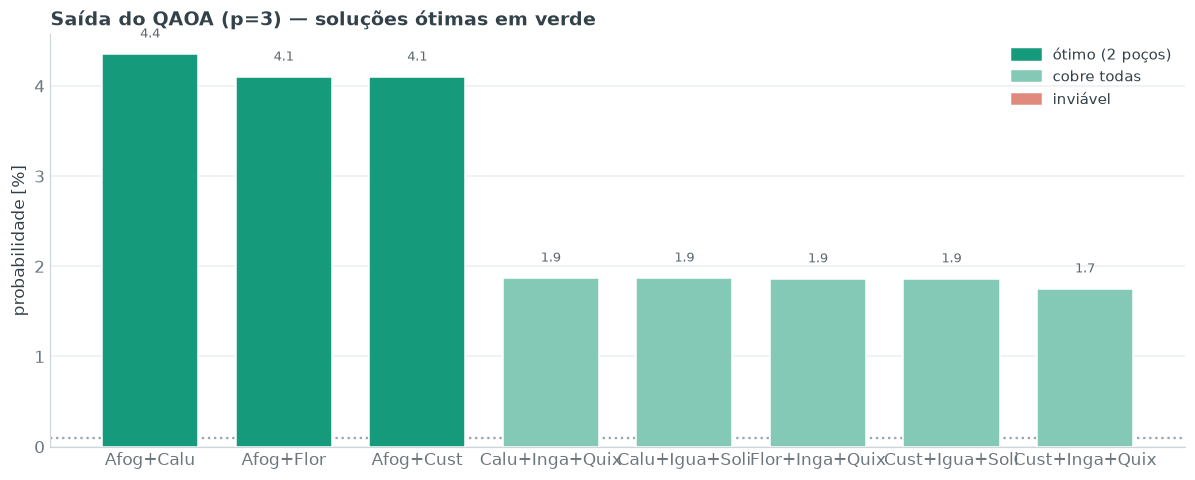

In [15]:
def rotulo(k):
    ps=pocos(k); return "+".join(c[:4] for c in ps) if ps else "∅"
def cor(k): return PAL["otimo"] if energies[k]==gmin else (PAL["viavel"] if feasible[k] else PAL["inviavel"])
topo=np.argsort(pr)[::-1][:8]
fig,ax=plt.subplots(figsize=(11,4.5)); clean(ax)
bars=ax.bar([rotulo(k) for k in topo],[pr[k]*100 for k in topo],color=[cor(k) for k in topo],edgecolor="white",width=0.72,zorder=3)
ax.axhline(100/2**n,ls=":",color=PAL["cinza"]); ax.set_ylabel("probabilidade [%]")
ax.set_title(f"Saída do QAOA (p={p_star}) — soluções ótimas em verde",loc="left")
for r,k in zip(bars,topo): ax.text(r.get_x()+r.get_width()/2,r.get_height()+0.15,f"{pr[k]*100:.1f}",ha="center",va="bottom",fontsize=8.5,color="#5b666d")
ax.legend(handles=[Patch(color=PAL["otimo"],label="ótimo (2 poços)"),Patch(color=PAL["viavel"],label="cobre todas"),Patch(color=PAL["inviavel"],label="inviável")],
          loc="upper right",frameon=False,fontsize=9.5)
plt.tight_layout(); plt.show()


### 4.3 A solução no mapa

O par ótimo mais provável do QAOA e suas áreas de serviço.

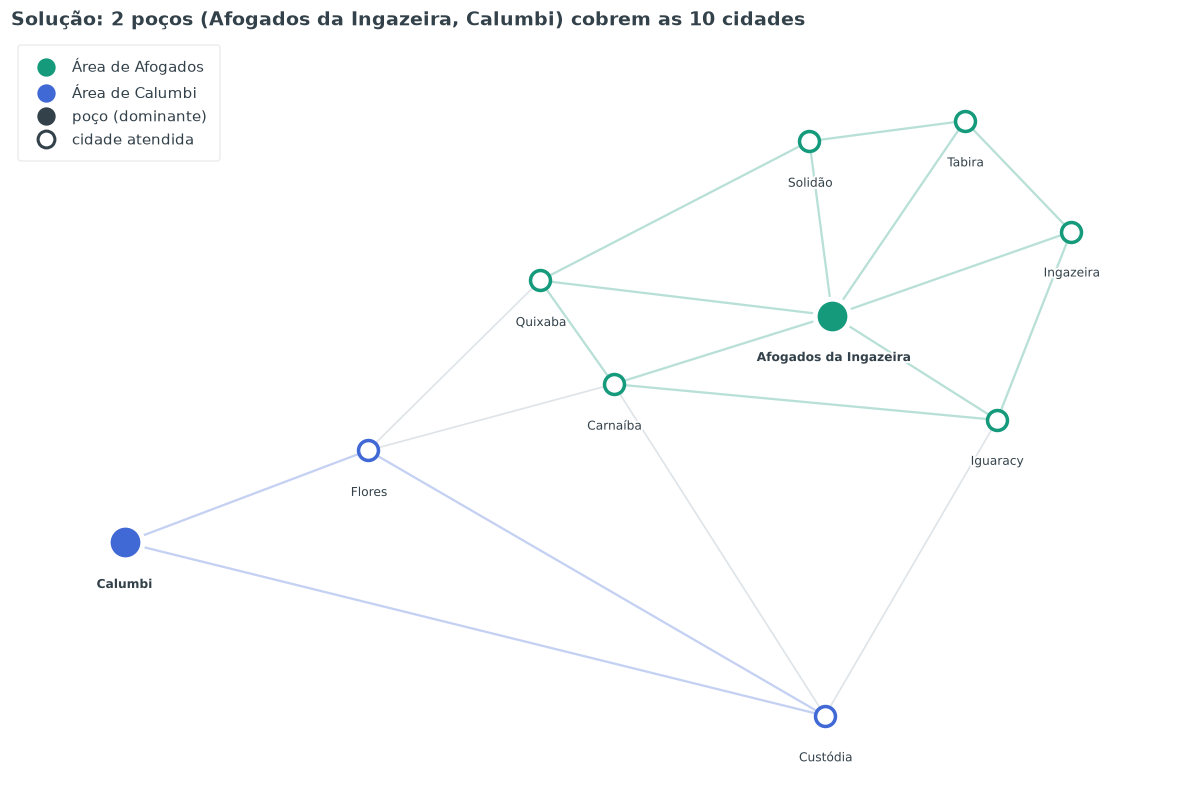

In [16]:
melhor_show=int(max(otimos,key=lambda k:pr[k])); ws=pocos(melhor_show)
wi=[i for i in range(n) if (melhor_show>>i)&1]
COL={wi[0]:PAL["otimo"],wi[1]:PAL["azul"]}
Dpos={i:np.array(pos[i]) for i in range(n)}
# território = poço que de fato COBRE a cidade (está em N[i]); se >1, o mais próximo
terr={i:min([w for w in wi if w in N[i]],key=lambda w:np.hypot(*(Dpos[i]-Dpos[w]))) for i in range(n)}
for w in wi: terr[w]=w
fig,ax=plt.subplots(figsize=(11,7.5))
for u,v in G.edges():
    iu,iv=cidades.index(u),cidades.index(v)
    if terr[iu]==terr[iv]: ax.plot([coord[u][0],coord[v][0]],[coord[u][1],coord[v][1]],color=COL[terr[iu]],alpha=0.30,lw=1.5,zorder=1)
    else: ax.plot([coord[u][0],coord[v][0]],[coord[u][1],coord[v][1]],color=PAL["edge"],lw=1.1,zorder=0)
for i in range(n):
    c=COL[terr[i]]; w=i in wi
    if w:
        ax.scatter(*pos[i],s=620,color="white",zorder=4); ax.scatter(*pos[i],s=470,color=c,edgecolors="white",linewidths=2.2,zorder=5)
    else:
        ax.scatter(*pos[i],s=170,color="white",edgecolors=c,linewidths=2.3,zorder=5)
    halo(ax.text(pos[i][0],pos[i][1]-0.03,cidades[i],ha="center",va="top",fontsize=8,fontweight="bold" if w else "normal",color=INK,zorder=6))
h=[Line2D([0],[0],marker='o',color='w',markerfacecolor=COL[w],markersize=13,label=f"Área de {cidades[w].split(' da')[0].split(' do')[0]}") for w in wi]
h+=[Line2D([0],[0],marker='o',color='w',markerfacecolor=INK,markersize=13,label="poço (dominante)"),
    Line2D([0],[0],marker='o',color='w',markerfacecolor="white",markeredgecolor=INK,markeredgewidth=2,markersize=11,label="cidade atendida")]
lg=ax.legend(handles=h,loc="upper left",frameon=True,fontsize=9.5,borderpad=0.9,labelspacing=0.6); lg.get_frame().set_edgecolor("#e6e9ec")
ax.set_title(f"Solução: 2 poços ({', '.join(ws)}) cobrem as 10 cidades",loc="left",pad=8)
xs=[p[0] for p in coord.values()]; ys=[p[1] for p in coord.values()]
mx=(max(xs)-min(xs))*0.12; my=(max(ys)-min(ys))*0.14
ax.set_xlim(min(xs)-mx,max(xs)+mx); ax.set_ylim(min(ys)-my,max(ys)+my); ax.set_axis_off()
plt.tight_layout(); plt.show()


## 5. Conclusão

- **Núcleo central do Pajeú (10 cidades):** mínimo **2 poços**, com **3 ótimos empatados** —
  Afogados (sempre) + {Calumbi | Custódia | Flores}. Afogados é o hub indispensável.
- **QAOA a 10 qubits — a transição de escala:** não crava tão limpo quanto os clusters de 5–6
  (P(ótimo) ~0,12 no melhor $p$, contra ~0,003 do acaso), **mas** aprende a viabilidade
  (P(viável) ~0,9) e a **amostragem recupera o ótimo** (melhor de 4096 medições = 2 poços). É um
  bom heurístico — ainda melhor que o brute force? Não a este tamanho ($2^{10}$ é trivial).

| Cluster | qubits | ótimo | QAOA |
|---|---|---|---|
| Pajeú-5 | 5 | 1 | crava (P≈0,38) |
| Araripe-6 | 6 | 2 | crava (P≈0,24) |
| **Pajeú-10** | 10 | 2 | **recupera via amostragem** (P(ótimo)≈0,12) |
| Pajeú-18 | 18 | 3 | heurístico fraco (P(ótimo)≈0) |

- **Hardware:** a 10 qubits o custo transpila para ~1.900 portas de 2 qubits (fidelidade ~10⁻⁶)
  → ainda ruído demais para rodar de verdade. O limite prático de hardware continua nos clusters
  de 5–6 qubits.
